<a href="https://colab.research.google.com/github/Sanhith30/deepLearning-csa4704/blob/main/CO1-Assignment%E2%80%99%201/Assignment_1_CO1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ITA06 – Machine Learning Assignment 1
## Complete Python implementation and experiments

**Topic:** Academic Early-Warning Decision Support System using Concept Learning, Candidate Elimination and ID3 Decision Trees  
**Coverage:** Tasks 1–11 (computational work, algorithms, validation, plots and Day-4 design challenge)

This notebook is self-contained. The assignment's Dataset A, Dataset B, and Test Set T are entered directly from the supplied assignment sheet. Dataset C is generated reproducibly with a documented synthetic rule and fixed random seeds.

**How to use:** Run the cells from top to bottom. The notebook creates `dataset_C_synthetic.csv` and a `figures/` folder in the current working directory. The decision-tree and Candidate Elimination logic is implemented here rather than delegated to scikit-learn.

**Important:** Dataset C is synthetic and is used only for controlled scalability/noise experiments. Its results must not be presented as real university performance.

## 0. Environment and imports

The notebook uses Python's standard library, NumPy, pandas and Matplotlib. It does not call a library implementation of Candidate Elimination or the main ID3 decision tree.

In [1]:
from __future__ import annotations

import itertools
import math
import random
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 2026
RNG = random.Random(SEED)
OUTPUT_DIR = Path.cwd()
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

print("Python environment ready")
print("Working directory:", OUTPUT_DIR)
print("Figures directory:", FIG_DIR)

Python environment ready
Working directory: /content
Figures directory: /content/figures


## 1. Enter the assignment datasets

Dataset A has six categorical attributes. Dataset B and Test Set T have four categorical attributes. The target class is `AtRisk`, with `Yes` treated as the positive class.

In [2]:
A_ATTRIBUTES = ["Attendance", "Assignments", "StudyHours", "PriorCGPA", "LMS", "Mentoring"]
A_DOMAINS = [
    ["Low", "Medium", "High"],
    ["Irregular", "Regular"],
    ["Low", "High"],
    ["Weak", "Strong"],
    ["Passive", "Active"],
    ["No", "Yes"],
]
DATASET_A = [
    ("E1", ("Low", "Irregular", "Low", "Weak", "Passive", "No"), "Yes"),
    ("E2", ("Low", "Irregular", "Low", "Strong", "Passive", "No"), "Yes"),
    ("E3", ("High", "Regular", "High", "Strong", "Active", "Yes"), "No"),
    ("E4", ("Low", "Irregular", "High", "Weak", "Passive", "Yes"), "Yes"),
    ("E5", ("Medium", "Irregular", "High", "Strong", "Active", "No"), "No"),
]

B_ATTRIBUTES = ["Attendance", "Assignments", "LMS", "PriorCGPA"]
B_DOMAINS = [
    ["Low", "Medium", "High"],
    ["Irregular", "Regular"],
    ["Passive", "Active"],
    ["Weak", "Strong"],
]
DATASET_B = [
    ("1", ("Low", "Irregular", "Passive", "Weak"), "Yes"),
    ("2", ("Low", "Irregular", "Passive", "Strong"), "Yes"),
    ("3", ("Low", "Regular", "Active", "Weak"), "Yes"),
    ("4", ("Low", "Regular", "Active", "Strong"), "No"),
    ("5", ("Medium", "Irregular", "Passive", "Weak"), "Yes"),
    ("6", ("Medium", "Irregular", "Active", "Strong"), "No"),
    ("7", ("Medium", "Regular", "Passive", "Weak"), "Yes"),
    ("8", ("Medium", "Regular", "Active", "Strong"), "No"),
    ("9", ("High", "Irregular", "Passive", "Weak"), "Yes"),
    ("10", ("High", "Irregular", "Active", "Strong"), "No"),
    ("11", ("High", "Regular", "Passive", "Strong"), "No"),
    ("12", ("High", "Regular", "Active", "Weak"), "No"),
    ("13", ("Medium", "Irregular", "Passive", "Strong"), "No"),
    ("14", ("Low", "Irregular", "Active", "Weak"), "Yes"),
]
TEST_SET_T = [
    ("T1", ("Low", "Irregular", "Active", "Strong"), "No"),
    ("T2", ("Medium", "Regular", "Active", "Weak"), "No"),
    ("T3", ("High", "Regular", "Passive", "Weak"), "Yes"),
    ("T4", ("Medium", "Irregular", "Active", "Weak"), "Yes"),
    ("T5", ("Low", "Regular", "Passive", "Strong"), "No"),
    ("T6", ("High", "Irregular", "Active", "Weak"), "Yes"),
]


def to_frame(rows, attributes):
    return pd.DataFrame(
        [{"ID": name, **dict(zip(attributes, instance)), "AtRisk": label}
         for name, instance, label in rows]
    )

print("Dataset A")
display(to_frame(DATASET_A, A_ATTRIBUTES))
print("Dataset B")
display(to_frame(DATASET_B, B_ATTRIBUTES))
print("Test Set T")
display(to_frame(TEST_SET_T, B_ATTRIBUTES))

Dataset A


,ID,Attendance,Assignments,StudyHours,PriorCGPA,LMS,Mentoring,AtRisk
0,E1,Low,Irregular,Low,Weak,Passive,No,Yes
1,E2,Low,Irregular,Low,Strong,Passive,No,Yes
2,E3,High,Regular,High,Strong,Active,Yes,No
3,E4,Low,Irregular,High,Weak,Passive,Yes,Yes
4,E5,Medium,Irregular,High,Strong,Active,No,No


Dataset B


,ID,Attendance,Assignments,LMS,PriorCGPA,AtRisk
0,1,Low,Irregular,Passive,Weak,Yes
1,2,Low,Irregular,Passive,Strong,Yes
2,3,Low,Regular,Active,Weak,Yes
3,4,Low,Regular,Active,Strong,No
4,5,Medium,Irregular,Passive,Weak,Yes
5,6,Medium,Irregular,Active,Strong,No
6,7,Medium,Regular,Passive,Weak,Yes
7,8,Medium,Regular,Active,Strong,No
8,9,High,Irregular,Passive,Weak,Yes
9,10,High,Irregular,Active,Strong,No


Test Set T


,ID,Attendance,Assignments,LMS,PriorCGPA,AtRisk
0,T1,Low,Irregular,Active,Strong,No
1,T2,Medium,Regular,Active,Weak,No
2,T3,High,Regular,Passive,Weak,Yes
3,T4,Medium,Irregular,Active,Weak,Yes
4,T5,Low,Regular,Passive,Strong,No
5,T6,High,Irregular,Active,Weak,Yes


## Task 1 – Identify and formulate the ML problem

The target is a Boolean concept over the categorical instance space. The calculations below compute the size of each instance space and the proportion represented by the supplied training records.

In [3]:
A_INSTANCE_SIZE = math.prod(len(d) for d in A_DOMAINS)
B_INSTANCE_SIZE = math.prod(len(d) for d in B_DOMAINS)
A_COVERAGE = len(DATASET_A) / A_INSTANCE_SIZE * 100
B_COVERAGE = len(DATASET_B) / B_INSTANCE_SIZE * 100

space_summary = pd.DataFrame([
    {"Dataset": "A", "Examples": len(DATASET_A), "Attributes": len(A_ATTRIBUTES),
     "Instance-space size": A_INSTANCE_SIZE, "Training coverage": f"{A_COVERAGE:.4f}%"},
    {"Dataset": "B", "Examples": len(DATASET_B), "Attributes": len(B_ATTRIBUTES),
     "Instance-space size": B_INSTANCE_SIZE, "Training coverage": f"{B_COVERAGE:.4f}%"},
])
display(space_summary)

attribute_table = pd.DataFrame([
    ["Attendance", "Categorical ordinal", "Low / Medium / High", "Engagement proxy; persistent low attendance can indicate missed instruction."],
    ["Assignments", "Categorical", "Irregular / Regular", "Submission consistency reflects participation and completion of coursework."],
    ["StudyHours", "Categorical", "Low / High", "Self-reported study time can reflect preparation, but may be imprecise."],
    ["PriorCGPA", "Categorical ordinal", "Weak / Strong", "Prior academic performance can provide historical evidence of preparedness."],
    ["LMS", "Categorical", "Passive / Active", "Learning-platform engagement can indicate whether a student accesses resources."],
    ["Mentoring", "Categorical", "No / Yes", "Records programme participation, but participation may be assigned in response to risk."],
], columns=["Attribute", "Type", "Values", "Why it may matter / caution"])
display(attribute_table)

issues_table = pd.DataFrame([
    ["Small sample", "Dataset A has only 5 examples and Dataset B has 14.", "Collect more semesters of records; use stratified validation and report uncertainty."],
    ["Low coverage", "Dataset A covers 5/96 = 5.2083% of its instance space.", "Track unseen combinations and evaluate on later cohorts."],
    ["Potential label noise", "Advisor-assigned AtRisk labels can differ between assessors.", "Use a shared rubric, adjudication and periodic label audits."],
    ["Sampling bias", "The five and fourteen records may not represent all departments or study modes.", "Audit performance by programme, year and relevant student groups."],
    ["Privacy", "Attendance, CGPA and platform activity are student records.", "Minimise collected fields, restrict access and define retention controls."],
    ["Fairness / proxy risk", "Mentoring may be a response to risk rather than a cause of it.", "Check whether the feature encodes unequal access or intervention decisions."],
], columns=["Issue", "Evidence in this scenario", "Mitigation"])
display(issues_table)

print("Formal T–P–E statement")
print("T: Predict whether a student will be AtRisk (Yes/No) after week 6.")
print("P: Prioritise recall for AtRisk=Yes, while also monitoring precision, F1 and confusion counts.")
print("E: Historical labelled student records with attendance, assignment, study, CGPA, LMS and mentoring attributes.")
print("Learning paradigm: supervised classification, because each training record includes an input vector and a council-assigned target label.")

,Dataset,Examples,Attributes,Instance-space size,Training coverage
0,A,5,6,96,5.2083%
1,B,14,4,24,58.3333%


,Attribute,Type,Values,Why it may matter / caution
0,Attendance,Categorical ordinal,Low / Medium / High,Engagement proxy; persistent low attendance can indicate missed instruction.
1,Assignments,Categorical,Irregular / Regular,Submission consistency reflects participation and completion of coursework.
2,StudyHours,Categorical,Low / High,"Self-reported study time can reflect preparation, but may be imprecise."
3,PriorCGPA,Categorical ordinal,Weak / Strong,Prior academic performance can provide historical evidence of preparedness.
4,LMS,Categorical,Passive / Active,Learning-platform engagement can indicate whether a student accesses resources.
5,Mentoring,Categorical,No / Yes,"Records programme participation, but participation may be assigned in response to risk."


,Issue,Evidence in this scenario,Mitigation
0,Small sample,Dataset A has only 5 examples and Dataset B has 14.,Collect more semesters of records; use stratified validation and report uncertainty.
1,Low coverage,Dataset A covers 5/96 = 5.2083% of its instance space.,Track unseen combinations and evaluate on later cohorts.
2,Potential label noise,Advisor-assigned AtRisk labels can differ between assessors.,"Use a shared rubric, adjudication and periodic label audits."
3,Sampling bias,The five and fourteen records may not represent all departments or study modes.,"Audit performance by programme, year and relevant student groups."
4,Privacy,"Attendance, CGPA and platform activity are student records.","Minimise collected fields, restrict access and define retention controls."
5,Fairness / proxy risk,Mentoring may be a response to risk rather than a cause of it.,Check whether the feature encodes unequal access or intervention decisions.


Formal T–P–E statement
T: Predict whether a student will be AtRisk (Yes/No) after week 6.
P: Prioritise recall for AtRisk=Yes, while also monitoring precision, F1 and confusion counts.
E: Historical labelled student records with attendance, assignment, study, CGPA, LMS and mentoring attributes.
Learning paradigm: supervised classification, because each training record includes an input vector and a council-assigned target label.


## Task 2 – Compare the learning paradigms in this scenario

The following matrix is scenario-specific. Supervised learning is selected for the initial binary early-warning output. Unsupervised and reinforcement learning may support profiling and intervention scheduling, respectively, but they do not replace the labelled risk classifier.

In [4]:
paradigm_matrix = pd.DataFrame([
    ["Supervised", "Available: Yes/No labels", "Risk class and score", "Difference between prediction and known label", "Historical labelled student records", "Held-out accuracy, precision, recall, F1; recall emphasised", "Can be explained with a small decision tree", "Label noise, bias and overfitting"],
    ["Unsupervised", "Not required", "Clusters / behavioural profiles", "No direct target feedback; structure is inferred from inputs", "Unlabelled student activity records", "Cluster stability and usefulness to advisors; no direct AtRisk accuracy", "Profiles can be described, but clusters do not automatically mean risk", "Clusters may not align with academic failure"],
    ["Reinforcement", "No fixed label per record; reward follows actions", "Intervention action / policy", "Reward after intervention outcome", "Longitudinal states, actions and outcomes", "Cumulative reward and intervention outcomes", "Policy may be difficult to explain", "Unsafe exploration, delayed reward and confounding"],
], columns=["Paradigm", "Labels", "Output", "Feedback", "Data needed", "Evaluation", "Advisor interpretability", "Main risk"])
display(paradigm_matrix)

print("Unsupervised example: cluster attendance, assignment, LMS and study patterns into engagement profiles.")
print("Limit: a cluster label does not establish whether a student will fail; it cannot directly produce the supervised AtRisk decision without labelled interpretation and validation.")
print("Reinforcement-learning follow-up example:")
print("  State = current risk score, attendance trend, missing assignments and prior interventions.")
print("  Action = schedule mentoring, remedial class, advisor contact, or no additional action.")
print("  Reward = improved course completion/attendance minus intervention cost and student burden.")
print("RL is not the initial classifier because the supplied examples have fixed end-of-semester labels, not sequential action/reward trajectories.")
print("Hybrid use: cluster engagement profiles to tailor intervention messages, while a supervised classifier provides the risk estimate.")

,Paradigm,Labels,Output,Feedback,Data needed,Evaluation,Advisor interpretability,Main risk
0,Supervised,Available: Yes/No labels,Risk class and score,Difference between prediction and known label,Historical labelled student records,"Held-out accuracy, precision, recall, F1; recall emphasised",Can be explained with a small decision tree,"Label noise, bias and overfitting"
1,Unsupervised,Not required,Clusters / behavioural profiles,No direct target feedback; structure is inferred from inputs,Unlabelled student activity records,Cluster stability and usefulness to advisors; no direct AtRisk accuracy,"Profiles can be described, but clusters do not automatically mean risk",Clusters may not align with academic failure
2,Reinforcement,No fixed label per record; reward follows actions,Intervention action / policy,Reward after intervention outcome,"Longitudinal states, actions and outcomes",Cumulative reward and intervention outcomes,Policy may be difficult to explain,"Unsafe exploration, delayed reward and confounding"


Unsupervised example: cluster attendance, assignment, LMS and study patterns into engagement profiles.
Limit: a cluster label does not establish whether a student will fail; it cannot directly produce the supervised AtRisk decision without labelled interpretation and validation.
Reinforcement-learning follow-up example:
  State = current risk score, attendance trend, missing assignments and prior interventions.
  Action = schedule mentoring, remedial class, advisor contact, or no additional action.
  Reward = improved course completion/attendance minus intervention cost and student burden.
RL is not the initial classifier because the supplied examples have fixed end-of-semester labels, not sequential action/reward trajectories.
Hybrid use: cluster engagement profiles to tailor intervention messages, while a supervised classifier provides the risk estimate.


## Task 3 – Formulate concept learning with Dataset A

A hypothesis is a conjunction of six attribute constraints. A specific attribute value constrains that position, `?` accepts any value, and `∅` denotes the empty/specific boundary symbol. The concept is `c(x)=1` for AtRisk=Yes and `c(x)=0` for AtRisk=No.

In [5]:
# Number of ordinary conjunctive hypotheses: one domain value or ? per attribute.
SYNTACTIC_HYPOTHESES_A = math.prod(len(d) + 1 for d in A_DOMAINS)
SEMANTIC_HYPOTHESES_A = SYNTACTIC_HYPOTHESES_A + 1  # add the all-empty bottom concept

print("Syntactically distinct conjunctive hypotheses:", SYNTACTIC_HYPOTHESES_A)
print("Semantically distinct hypotheses including bottom:", SEMANTIC_HYPOTHESES_A)
print("Instance-space size:", A_INSTANCE_SIZE)

labelled_A = pd.DataFrame([
    {"Example": name, **dict(zip(A_ATTRIBUTES, x)), "AtRisk": y,
     "Concept label c(x)": 1 if y == "Yes" else 0}
    for name, x, y in DATASET_A
])
display(labelled_A)

MOST_GENERAL = tuple("?" for _ in A_ATTRIBUTES)
MOST_SPECIFIC = tuple("∅" for _ in A_ATTRIBUTES)
E1_HYPOTHESIS = DATASET_A[0][1]
E3_HYPOTHESIS = DATASET_A[2][1]
print("Most general:", MOST_GENERAL)
print("Most specific:", MOST_SPECIFIC)
print("E1 as a hypothesis:", E1_HYPOTHESIS)
print("E3 as a hypothesis:", E3_HYPOTHESIS)

h1 = ("?", "Irregular", "?", "?", "?", "?")
h2 = ("Low", "Irregular", "?", "?", "?", "?")
h3 = ("High", "?", "?", "?", "?", "?")

def more_general_or_equal(h_general, h_specific):
    for general_value, specific_value in zip(h_general, h_specific):
        if specific_value == "∅":
            continue
        if general_value == "?":
            continue
        if general_value != specific_value:
            return False
    return True

print("h1 >= h2:", more_general_or_equal(h1, h2))
print("h3 comparable with h1:", more_general_or_equal(h3, h1) or more_general_or_equal(h1, h3))
print("h3 comparable with h2:", more_general_or_equal(h3, h2) or more_general_or_equal(h2, h3))


def hypothesis_matches(h, x):
    return all(v == "?" or v == x[i] for i, v in enumerate(h))

consistency_rows = []
for label, h in [
    ("h_a", ("Low", "?", "?", "?", "Passive", "?")),
    ("h_b", ("?", "Irregular", "?", "?", "?", "?")),
    ("h_c", ("Low", "Irregular", "Low", "?", "?", "?")),
]:
    matched = [name for name, x, y in DATASET_A if hypothesis_matches(h, x)]
    conflicts = [name for name, x, y in DATASET_A if hypothesis_matches(h, x) and y == "No"]
    consistency_rows.append({"Hypothesis": label, "Tuple": h, "Covered examples": ", ".join(matched),
                             "Negative examples covered": ", ".join(conflicts) or "None",
                             "Consistent with all training labels": len(conflicts) == 0})
display(pd.DataFrame(consistency_rows))

Syntactically distinct conjunctive hypotheses: 972
Semantically distinct hypotheses including bottom: 973
Instance-space size: 96


,Example,Attendance,Assignments,StudyHours,PriorCGPA,LMS,Mentoring,AtRisk,Concept label c(x)
0,E1,Low,Irregular,Low,Weak,Passive,No,Yes,1
1,E2,Low,Irregular,Low,Strong,Passive,No,Yes,1
2,E3,High,Regular,High,Strong,Active,Yes,No,0
3,E4,Low,Irregular,High,Weak,Passive,Yes,Yes,1
4,E5,Medium,Irregular,High,Strong,Active,No,No,0


Most general: ('?', '?', '?', '?', '?', '?')
Most specific: ('∅', '∅', '∅', '∅', '∅', '∅')
E1 as a hypothesis: ('Low', 'Irregular', 'Low', 'Weak', 'Passive', 'No')
E3 as a hypothesis: ('High', 'Regular', 'High', 'Strong', 'Active', 'Yes')
h1 >= h2: True
h3 comparable with h1: False
h3 comparable with h2: False


,Hypothesis,Tuple,Covered examples,Negative examples covered,Consistent with all training labels
0,h_a,"(Low, ?, ?, ?, Passive, ?)","E1, E2, E4",None,True
1,h_b,"(?, Irregular, ?, ?, ?, ?)","E1, E2, E4, E5",E5,False
2,h_c,"(Low, Irregular, Low, ?, ?, ?)","E1, E2",None,True


## Candidate Elimination implementation used in Tasks 4, 5, 9, 10 and 11

The code maintains the specific boundary `S` and general boundary `G`. It also records candidate specialisations rejected because they would be more specific than every member of `S`. A version space is enumerated from the boundary sets for this small finite hypothesis space.

In [6]:
Hypothesis = Tuple[str, ...]


def covers(h: Hypothesis, x: Sequence[str]) -> bool:
    return all(value == "?" or value == x[i] for i, value in enumerate(h))


def minimal_generalization(s: Hypothesis, x: Sequence[str]) -> Hypothesis:
    result = []
    for i, value in enumerate(s):
        if value == "∅":
            result.append(x[i])
        elif value == x[i] or value == "?":
            result.append(value)
        else:
            result.append("?")
    return tuple(result)


def minimal_specializations(g: Hypothesis, x: Sequence[str], domains, S_set):
    accepted, rejected = set(), set()
    for i, value in enumerate(g):
        if value != "?":
            continue
        for alternative in domains[i]:
            if alternative == x[i]:
                continue
            candidate = list(g)
            candidate[i] = alternative
            candidate = tuple(candidate)
            # Standard CE condition: keep it if it remains >= at least one S member.
            if any(more_general_or_equal(candidate, s) for s in S_set):
                accepted.add(candidate)
            else:
                rejected.add(candidate)
    return accepted, rejected


def prune_S(candidate_S):
    return {s for s in candidate_S
            if not any(s != other and more_general_or_equal(s, other)
                       for other in candidate_S)}


def prune_G(candidate_G):
    return {g for g in candidate_G
            if not any(g != other and more_general_or_equal(other, g)
                       for other in candidate_G)}


def enumerate_version_space(S_set, G_set, domains):
    if not S_set or not G_set:
        return []
    choices = [list(domain) + ["?"] for domain in domains]
    valid = []
    for h in itertools.product(*choices):
        if (all(more_general_or_equal(g, h) for g in G_set)
                and all(more_general_or_equal(h, s) for s in S_set)):
            valid.append(tuple(h))
    return sorted(valid)


def candidate_elimination(data, domains):
    n = len(domains)
    S = {tuple("∅" for _ in range(n))}
    G = {tuple("?" for _ in range(n))}
    trace = []

    for name, x, label in data:
        before_S, before_G = set(S), set(G)
        details = []
        if label == "Yes":
            # Remove any G hypothesis that does not cover the positive example.
            removed_G = {g for g in G if not covers(g, x)}
            G = {g for g in G if covers(g, x)}
            generalized = []
            candidates_S = set()
            for s in S:
                if covers(s, x):
                    candidates_S.add(s)
                else:
                    new_s = minimal_generalization(s, x)
                    generalized.append((s, new_s))
                    candidates_S.add(new_s)
            S = prune_S(candidates_S)
            details.append({"type": "positive", "generalized": generalized,
                            "removed_G": sorted(removed_G)})
        else:
            candidates_G = set()
            specialisation_detail = []
            for g in G:
                if not covers(g, x):
                    candidates_G.add(g)
                    continue
                accepted, rejected = minimal_specializations(g, x, domains, S)
                candidates_G |= accepted
                specialisation_detail.append({"from": g, "accepted": sorted(accepted),
                                              "rejected": sorted(rejected)})
            G = prune_G(candidates_G)
            details.append({"type": "negative", "specialisations": specialisation_detail})

        vs = enumerate_version_space(S, G, domains)
        trace.append({"example": name, "instance": x, "label": label,
                      "before_S": sorted(before_S), "before_G": sorted(before_G),
                      "S": sorted(S), "G": sorted(G), "version_space": vs,
                      "details": details})
    return S, G, trace


def display_hypotheses(items):
    return "{ " + "; ".join("⟨" + ", ".join(h) + "⟩" for h in items) + " }"

## Task 4 – Apply Candidate Elimination to Dataset A

Examples are processed in the required order E1 → E5. Each row reports the boundaries after processing the example and the version-space size. Detailed generalisation and specialisation actions are displayed beneath the table.

In [7]:
S_A, G_A, TRACE_A = candidate_elimination(DATASET_A, A_DOMAINS)
trace_table = []
for item in TRACE_A:
    trace_table.append({
        "Step": item["example"],
        "Label": item["label"],
        "Action": "Generalise S" if item["label"] == "Yes" else "Specialise G",
        "S after update": display_hypotheses(item["S"]),
        "G after update": display_hypotheses(item["G"]),
        "|VS|": len(item["version_space"]),
    })
display(pd.DataFrame(trace_table))

for item in TRACE_A:
    print(f"\n{item['example']} ({item['label']})")
    for detail in item["details"]:
        if detail["type"] == "positive":
            print("  Minimal S generalisations:")
            for old, new in detail["generalized"]:
                print("   ", old, "->", new)
            print("  G hypotheses removed for not covering example:", detail["removed_G"])
        else:
            for record in detail["specialisations"]:
                print("  Specialising G member:", record["from"])
                print("   Accepted minimal specialisations:", record["accepted"])
                print("   Rejected (not >= any S member):", record["rejected"])
    print("  S =", display_hypotheses(item["S"]))
    print("  G =", display_hypotheses(item["G"]))
    print("  Version-space size =", len(item["version_space"]))

print("\nFinal S5:", display_hypotheses(sorted(S_A)))
print("Final G5:", display_hypotheses(sorted(G_A)))
print("Final version space:")
for h in enumerate_version_space(S_A, G_A, A_DOMAINS):
    print(" ", h)

,Step,Label,Action,S after update,G after update,|VS|
0,E1,Yes,Generalise S,"{ ⟨Low, Irregular, Low, Weak, Passive, No⟩ }","{ ⟨?, ?, ?, ?, ?, ?⟩ }",64
1,E2,Yes,Generalise S,"{ ⟨Low, Irregular, Low, ?, Passive, No⟩ }","{ ⟨?, ?, ?, ?, ?, ?⟩ }",32
2,E3,No,Specialise G,"{ ⟨Low, Irregular, Low, ?, Passive, No⟩ }","{ ⟨?, ?, ?, ?, ?, No⟩; ⟨?, ?, ?, ?, Passive, ?⟩; ⟨?, ?, Low, ?, ?, ?⟩; ⟨?, Irregular, ?, ?, ?, ?...",1
3,E4,Yes,Generalise S,"{ ⟨Low, Irregular, ?, ?, Passive, ?⟩ }","{ ⟨?, ?, ?, ?, Passive, ?⟩; ⟨?, Irregular, ?, ?, ?, ?⟩; ⟨Low, ?, ?, ?, ?, ?⟩ }",1
4,E5,No,Specialise G,"{ ⟨Low, Irregular, ?, ?, Passive, ?⟩ }","{ ⟨?, ?, ?, ?, Passive, ?⟩; ⟨Low, ?, ?, ?, ?, ?⟩ }",2



E1 (Yes)
  Minimal S generalisations:
    ('∅', '∅', '∅', '∅', '∅', '∅') -> ('Low', 'Irregular', 'Low', 'Weak', 'Passive', 'No')
  G hypotheses removed for not covering example: []
  S = { ⟨Low, Irregular, Low, Weak, Passive, No⟩ }
  G = { ⟨?, ?, ?, ?, ?, ?⟩ }
  Version-space size = 64

E2 (Yes)
  Minimal S generalisations:
    ('Low', 'Irregular', 'Low', 'Weak', 'Passive', 'No') -> ('Low', 'Irregular', 'Low', '?', 'Passive', 'No')
  G hypotheses removed for not covering example: []
  S = { ⟨Low, Irregular, Low, ?, Passive, No⟩ }
  G = { ⟨?, ?, ?, ?, ?, ?⟩ }
  Version-space size = 32

E3 (No)
  Specialising G member: ('?', '?', '?', '?', '?', '?')
   Accepted minimal specialisations: [('?', '?', '?', '?', '?', 'No'), ('?', '?', '?', '?', 'Passive', '?'), ('?', '?', 'Low', '?', '?', '?'), ('?', 'Irregular', '?', '?', '?', '?'), ('Low', '?', '?', '?', '?', '?')]
   Rejected (not >= any S member): [('?', '?', '?', 'Weak', '?', '?'), ('Medium', '?', '?', '?', '?', '?')]
  S = { ⟨Low, Irre

## Task 5 – Version space, queries and inductive bias

This cell enumerates the final version space, creates a small general-to-specific lattice, compares query votes and demonstrates how one additional positive example changes the version space.

Final version-space size: 2
Hypotheses:
  ('Low', '?', '?', '?', 'Passive', '?')
  ('Low', 'Irregular', '?', '?', 'Passive', '?')


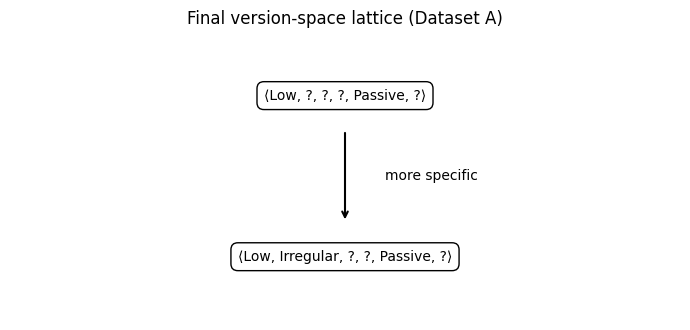

,Query,Instance,Yes votes,No votes,Vote outcome
0,Q1,"(Low, Regular, High, Weak, Passive, No)",1,1,Ambiguous
1,Q2,"(Low, Irregular, Low, Strong, Passive, Yes)",2,0,Yes


Most informative of the two supplied queries: Q1, because it splits the two surviving hypotheses one vote each.


,Term,Example in this assignment,Meaning
0,Training data,E1–E5,Observed labelled examples used to constrain learning.
1,Hypothesis space,972 ordinary conjunctive hypotheses (+ bottom),All candidate conjunctions expressible by the chosen representation.
2,Version space,2 hypotheses after E1–E5,Only hypotheses consistent with every supplied labelled example.
3,Inductive bias,Conjunction of attribute constraints,Assumes the target can be represented in this restricted form.



After adding the required positive example:
S = { ⟨?, ?, ?, ?, Passive, ?⟩ }
G = { ⟨?, ?, ?, ?, Passive, ?⟩ }
Version-space size = 1
Version space = [('?', '?', '?', '?', 'Passive', '?')]
Power set of the instance space: 2^96 possible Boolean concepts ( 7.922816e+28 ).
An unrestricted power-set learner has no useful representation bias to prefer one unseen-instance classification over another.


In [8]:
FINAL_VS_A = enumerate_version_space(S_A, G_A, A_DOMAINS)
print("Final version-space size:", len(FINAL_VS_A))
print("Hypotheses:")
for h in FINAL_VS_A:
    print(" ", h)

# The broad hypothesis is above the narrower one in the general-to-specific ordering.
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axis("off")
positions = {FINAL_VS_A[1]: (0.5, 0.78), FINAL_VS_A[0]: (0.5, 0.22)} if len(FINAL_VS_A) == 2 else {}
if len(FINAL_VS_A) == 2:
    broad = next(h for h in FINAL_VS_A if h[1] == "?")
    narrow = next(h for h in FINAL_VS_A if h[1] == "Irregular")
    ax.text(0.5, 0.78, "⟨" + ", ".join(broad) + "⟩", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="black"))
    ax.text(0.5, 0.22, "⟨" + ", ".join(narrow) + "⟩", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="black"))
    ax.annotate("", xy=(0.5, 0.34), xytext=(0.5, 0.66), arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.text(0.56, 0.5, "more specific", va="center")
ax.set_title("Final version-space lattice (Dataset A)")
plt.tight_layout()
plt.show()

Q1 = ("Low", "Regular", "High", "Weak", "Passive", "No")
Q2 = ("Low", "Irregular", "Low", "Strong", "Passive", "Yes")
query_rows = []
for query_name, query in [("Q1", Q1), ("Q2", Q2)]:
    yes_votes = sum(covers(h, query) for h in FINAL_VS_A)
    no_votes = len(FINAL_VS_A) - yes_votes
    query_rows.append({"Query": query_name, "Instance": query, "Yes votes": yes_votes,
                       "No votes": no_votes, "Vote outcome": "Yes" if yes_votes > no_votes else ("No" if no_votes > yes_votes else "Ambiguous")})
display(pd.DataFrame(query_rows))

# A balanced vote is the most informative query here because it splits the current version space.
best_query = max([(abs(sum(covers(h, q) for h in FINAL_VS_A) - len(FINAL_VS_A)/2), name, q)
                  for name, q in [("Q1", Q1), ("Q2", Q2)]], key=lambda z: -z[0])
print("Most informative of the two supplied queries: Q1, because it splits the two surviving hypotheses one vote each.")

concept_distinction = pd.DataFrame([
    ["Training data", "E1–E5", "Observed labelled examples used to constrain learning."],
    ["Hypothesis space", "972 ordinary conjunctive hypotheses (+ bottom)", "All candidate conjunctions expressible by the chosen representation."],
    ["Version space", "2 hypotheses after E1–E5", "Only hypotheses consistent with every supplied labelled example."],
    ["Inductive bias", "Conjunction of attribute constraints", "Assumes the target can be represented in this restricted form."],
], columns=["Term", "Example in this assignment", "Meaning"])
display(concept_distinction)

extra_positive = ("E6_added_for_Task5", ("High", "Regular", "High", "Strong", "Passive", "No"), "Yes")
S_plus, G_plus, trace_plus = candidate_elimination(DATASET_A + [extra_positive], A_DOMAINS)
VS_plus = enumerate_version_space(S_plus, G_plus, A_DOMAINS)
print("\nAfter adding the required positive example:")
print("S =", display_hypotheses(sorted(S_plus)))
print("G =", display_hypotheses(sorted(G_plus)))
print("Version-space size =", len(VS_plus))
print("Version space =", VS_plus)
print("Power set of the instance space: 2^96 possible Boolean concepts (", f"{2**96:.6e}", ").")
print("An unrestricted power-set learner has no useful representation bias to prefer one unseen-instance classification over another.")

## ID3 decision-tree implementation used in Tasks 6–11

Entropy, information gain and recursive splitting are implemented directly. The deterministic tie-break selects the earliest remaining attribute in the input attribute order. A node stops if it is pure, has no attributes left, reaches the configured maximum depth, has fewer than `min_samples_split` records, or its best gain is below `min_gain`.

In [9]:
@dataclass
class TreeNode:
    attribute: Optional[int] = None
    prediction: Optional[str] = None
    branches: Dict[str, "TreeNode"] = field(default_factory=dict)
    counts: Counter = field(default_factory=Counter)
    default_prediction: str = "Yes"
    depth: int = 0


def entropy(rows) -> float:
    counts = Counter(label for _, _, label in rows)
    n = len(rows)
    if n == 0:
        return 0.0
    return -sum((count / n) * math.log2(count / n)
                for count in counts.values() if count > 0)


def majority_class(rows, default="Yes") -> str:
    counts = Counter(label for _, _, label in rows)
    if not counts:
        return default
    # Conservative policy: ties are assigned to AtRisk=Yes to reduce false negatives.
    return "Yes" if counts["Yes"] >= counts["No"] else "No"


def split_details(rows, attribute_index):
    subsets = defaultdict(list)
    for row in rows:
        subsets[row[1][attribute_index]].append(row)
    base_entropy = entropy(rows)
    weighted_entropy = sum(len(subset) / len(rows) * entropy(subset)
                           for subset in subsets.values())
    information_gain = base_entropy - weighted_entropy
    split_information = -sum((len(subset) / len(rows)) * math.log2(len(subset) / len(rows))
                             for subset in subsets.values() if len(subset))
    gain_ratio = information_gain / split_information if split_information else 0.0
    return subsets, base_entropy, weighted_entropy, information_gain, split_information, gain_ratio


def build_id3(rows, attributes, domains, features=None, max_depth=None,
              min_samples_split=2, min_gain=1e-12, depth=0, default="Yes",
              gain_log=None, path="ROOT"):
    if gain_log is None:
        gain_log = []
    if features is None:
        features = list(range(len(attributes)))
    counts = Counter(label for _, _, label in rows)
    majority = majority_class(rows, default)

    if len(counts) <= 1:
        pure_label = next(iter(counts)) if counts else default
        return TreeNode(prediction=pure_label, counts=counts,
                        default_prediction=majority, depth=depth)
    if (not features or (max_depth is not None and depth >= max_depth)
            or len(rows) < min_samples_split):
        return TreeNode(prediction=majority, counts=counts,
                        default_prediction=majority, depth=depth)

    candidate_gains = []
    for i in features:
        split = split_details(rows, i)
        candidate_gains.append((split[3], i))
        gain_log.append({"Node path": path, "Node depth": depth, "Node size": len(rows),
                         "Class counts": dict(counts), "Candidate attribute": attributes[i],
                         "Entropy before split": split[1], "Weighted entropy": split[2],
                         "Information gain": split[3]})
    best_gain, best_attribute = max(candidate_gains,
                                   key=lambda item: (item[0], -features.index(item[1])))
    if best_gain < min_gain:
        return TreeNode(prediction=majority, counts=counts,
                        default_prediction=majority, depth=depth)

    subsets = split_details(rows, best_attribute)[0]
    node = TreeNode(attribute=best_attribute, counts=counts,
                    default_prediction=majority, depth=depth)
    remaining = [i for i in features if i != best_attribute]
    for value in domains[best_attribute]:
        if value in subsets:
            node.branches[value] = build_id3(
                subsets[value], attributes, domains, remaining, max_depth,
                min_samples_split, min_gain, depth + 1, majority, gain_log,
                path + f" / {attributes[best_attribute]}={value}")
        else:
            node.branches[value] = TreeNode(prediction=majority, counts=Counter(),
                                            default_prediction=majority, depth=depth + 1)
    return node


def predict_tree(node: TreeNode, instance: Sequence[str]) -> str:
    current = node
    while current.attribute is not None:
        value = instance[current.attribute]
        # Unknown values fall back to the majority class at the current parent node.
        if value not in current.branches:
            return current.default_prediction
        current = current.branches[value]
    return current.prediction or "Yes"


def tree_statistics(node: TreeNode):
    if node.attribute is None:
        return 1, 1, node.depth
    children = [tree_statistics(child) for child in node.branches.values()]
    return (1 + sum(item[0] for item in children),
            sum(item[1] for item in children),
            max(item[2] for item in children))


def tree_as_text(node: TreeNode, attributes, indent="") -> str:
    lines = []
    if node.attribute is None:
        return indent + f"Predict {node.prediction}  counts={dict(node.counts)}"
    lines.append(indent + f"Split on {attributes[node.attribute]}  counts={dict(node.counts)}")
    for value, child in node.branches.items():
        lines.append(indent + f"  [{value}]")
        lines.append(tree_as_text(child, attributes, indent + "    "))
    return "\n".join(lines)


def tree_rules(node: TreeNode, attributes, conditions=None):
    if conditions is None:
        conditions = []
    if node.attribute is None:
        left = " AND ".join(conditions) if conditions else "TRUE"
        return [f"IF {left} THEN AtRisk = {node.prediction}"]
    rules = []
    for value, child in node.branches.items():
        rules.extend(tree_rules(child, attributes,
                                conditions + [f"{attributes[node.attribute]} = {value}"]))
    return rules


def classification_metrics(rows, model):
    tp = fp = tn = fn = 0
    predictions = []
    for name, instance, actual in rows:
        predicted = predict_tree(model, instance)
        predictions.append((name, actual, predicted))
        if actual == "Yes" and predicted == "Yes": tp += 1
        elif actual == "No" and predicted == "Yes": fp += 1
        elif actual == "No" and predicted == "No": tn += 1
        else: fn += 1
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"TP": tp, "FP": fp, "TN": tn, "FN": fn,
            "accuracy": (tp + tn) / len(rows) if rows else 0.0,
            "precision": precision, "recall": recall, "f1": f1,
            "predictions": predictions}


def confusion_frame(metrics):
    return pd.DataFrame([[metrics["TN"], metrics["FP"]],
                         [metrics["FN"], metrics["TP"]]],
                        index=["Actual No", "Actual Yes"],
                        columns=["Predicted No", "Predicted Yes"])

## Task 6 – Construct the ID3 decision tree on Dataset B

First calculate the full-set entropy. Then calculate subset sizes, class counts, subset entropies, weighted entropy and information gain for each possible root attribute. The recursive gain log records the calculations at every impure decision node.

In [10]:
root_counts = Counter(y for _, _, y in DATASET_B)
H_B = entropy(DATASET_B)
print("Dataset B class counts:", dict(root_counts))
print(f"H(Dataset B) = {H_B:.6f} bits")

root_rows = []
for i, attribute in enumerate(B_ATTRIBUTES):
    subsets, base_h, weighted_h, gain, split_info, gain_ratio = split_details(DATASET_B, i)
    root_rows.append({"Attribute": attribute, "Subset details": "; ".join(
        f"{value}: n={len(part)}, counts={dict(Counter(y for _,_,y in part))}, H={entropy(part):.4f}"
        for value, part in subsets.items()),
        "Weighted entropy": weighted_h, "Information gain": gain})
display(pd.DataFrame(root_rows))

GAIN_LOG_B = []
TREE_B = build_id3(DATASET_B, B_ATTRIBUTES, B_DOMAINS, gain_log=GAIN_LOG_B)
recursive_gain_table = pd.DataFrame(GAIN_LOG_B)
print("Recursive split calculations (all candidate gains at every decision node):")
display(recursive_gain_table.round(6))

print("Final ID3 tree:")
print(tree_as_text(TREE_B, B_ATTRIBUTES))
print("\nIF–THEN rules:")
for rule in tree_rules(TREE_B, B_ATTRIBUTES):
    print(rule)

nodes_B, leaves_B, depth_B = tree_statistics(TREE_B)
train_metrics_B = classification_metrics(DATASET_B, TREE_B)
print(f"\nTree statistics: depth={depth_B}, nodes={nodes_B}, leaves={leaves_B}")
print(f"Training accuracy={train_metrics_B['accuracy']:.4f}")

Dataset B class counts: {'Yes': 7, 'No': 7}
H(Dataset B) = 1.000000 bits


,Attribute,Subset details,Weighted entropy,Information gain
0,Attendance,"Low: n=5, counts={'Yes': 4, 'No': 1}, H=0.7219; Medium: n=5, counts={'Yes': 2, 'No': 3}, H=0.971...",0.836393,0.163607
1,Assignments,"Irregular: n=8, counts={'Yes': 5, 'No': 3}, H=0.9544; Regular: n=6, counts={'Yes': 2, 'No': 4}, ...",0.938946,0.061054
2,LMS,"Passive: n=7, counts={'Yes': 5, 'No': 2}, H=0.8631; Active: n=7, counts={'Yes': 2, 'No': 5}, H=0...",0.863121,0.136879
3,PriorCGPA,"Weak: n=7, counts={'Yes': 6, 'No': 1}, H=0.5917; Strong: n=7, counts={'Yes': 1, 'No': 6}, H=0.5917",0.591673,0.408327


Recursive split calculations (all candidate gains at every decision node):


,Node path,Node depth,Node size,Class counts,Candidate attribute,Entropy before split,Weighted entropy,Information gain
0,ROOT,0,14,"{'Yes': 7, 'No': 7}",Attendance,1.000000,0.836393,0.163607
1,ROOT,0,14,"{'Yes': 7, 'No': 7}",Assignments,1.000000,0.938946,0.061054
2,ROOT,0,14,"{'Yes': 7, 'No': 7}",LMS,1.000000,0.863121,0.136879
3,ROOT,0,14,"{'Yes': 7, 'No': 7}",PriorCGPA,1.000000,0.591673,0.408327
4,ROOT / PriorCGPA=Weak,1,7,"{'Yes': 6, 'No': 1}",Attendance,0.591673,0.285714,0.305958
5,ROOT / PriorCGPA=Weak,1,7,"{'Yes': 6, 'No': 1}",Assignments,0.591673,0.393555,0.198117
6,ROOT / PriorCGPA=Weak,1,7,"{'Yes': 6, 'No': 1}",LMS,0.591673,0.393555,0.198117
7,ROOT / PriorCGPA=Weak / Attendance=High,2,2,"{'Yes': 1, 'No': 1}",Assignments,1.000000,0.000000,1.000000
8,ROOT / PriorCGPA=Weak / Attendance=High,2,2,"{'Yes': 1, 'No': 1}",LMS,1.000000,0.000000,1.000000
9,ROOT / PriorCGPA=Strong,1,7,"{'Yes': 1, 'No': 6}",Attendance,0.591673,0.285714,0.305958


Final ID3 tree:
Split on PriorCGPA  counts={'Yes': 7, 'No': 7}
  [Weak]
    Split on Attendance  counts={'Yes': 6, 'No': 1}
      [Low]
        Predict Yes  counts={'Yes': 3}
      [Medium]
        Predict Yes  counts={'Yes': 2}
      [High]
        Split on Assignments  counts={'Yes': 1, 'No': 1}
          [Irregular]
            Predict Yes  counts={'Yes': 1}
          [Regular]
            Predict No  counts={'No': 1}
  [Strong]
    Split on Attendance  counts={'Yes': 1, 'No': 6}
      [Low]
        Split on Assignments  counts={'Yes': 1, 'No': 1}
          [Irregular]
            Predict Yes  counts={'Yes': 1}
          [Regular]
            Predict No  counts={'No': 1}
      [Medium]
        Predict No  counts={'No': 3}
      [High]
        Predict No  counts={'No': 2}

IF–THEN rules:
IF PriorCGPA = Weak AND Attendance = Low THEN AtRisk = Yes
IF PriorCGPA = Weak AND Attendance = Medium THEN AtRisk = Yes
IF PriorCGPA = Weak AND Attendance = High AND Assignments = Irregular THEN AtR

## Task 7 – Heuristic search, gain ratio and alternative root

ID3 starts with a single unsplit node. The operator selects an attribute and creates branches. Information gain is the greedy evaluation heuristic. Search terminates when a node is pure or a stopping condition is reached. A unique StudentID would produce perfect training separation but would memorise records.

In [11]:
# Number of candidate attributes evaluated at each decision node and total gain computations.
per_node = (recursive_gain_table.groupby(["Node path", "Node depth"], as_index=False)
            .agg(**{"Candidates evaluated": ("Candidate attribute", "count"),
                  "Node size": ("Node size", "first")}))
display(per_node)
print("Total information-gain computations:", len(recursive_gain_table))

# Compare root information gain and gain ratio for Attendance and PriorCGPA.
ratio_rows = []
for attribute in ["Attendance", "PriorCGPA"]:
    i = B_ATTRIBUTES.index(attribute)
    subsets, base_h, weighted_h, gain, split_info, ratio = split_details(DATASET_B, i)
    ratio_rows.append({"Attribute": attribute, "Entropy before": base_h,
                       "Weighted entropy": weighted_h, "Information gain": gain,
                       "Split information": split_info, "Gain ratio": ratio})
display(pd.DataFrame(ratio_rows).round(6))

# StudentID has one unique branch per training record: each child is pure.
student_id_gain = entropy(DATASET_B)
student_id_split_info = math.log2(len(DATASET_B))
student_id_gain_ratio = student_id_gain / student_id_split_info
print(f"StudentID: entropy={H_B:.6f}, weighted entropy=0, information gain={student_id_gain:.6f}, "
      f"split information={student_id_split_info:.6f}, gain ratio={student_id_gain_ratio:.6f}")
print("A StudentID split memorises the 14 training rows and provides no defensible rule for a new student.")


def build_forced_root(rows, forced_attribute_index, attributes, domains,
                      max_depth=None, min_samples_split=2, min_gain=1e-12):
    parent_majority = majority_class(rows)
    subsets = split_details(rows, forced_attribute_index)[0]
    root = TreeNode(attribute=forced_attribute_index,
                    counts=Counter(y for _, _, y in rows),
                    default_prediction=parent_majority, depth=0)
    remaining = [i for i in range(len(attributes)) if i != forced_attribute_index]
    log = []
    for value in domains[forced_attribute_index]:
        if value in subsets:
            root.branches[value] = build_id3(subsets[value], attributes, domains,
                                              features=remaining, max_depth=max_depth,
                                              min_samples_split=min_samples_split,
                                              min_gain=min_gain, depth=1,
                                              default=parent_majority, gain_log=log,
                                              path=f"ROOT forced {attributes[forced_attribute_index]}={value}")
        else:
            root.branches[value] = TreeNode(prediction=parent_majority, counts=Counter(), depth=1)
    return root

ATTENDANCE_ROOT_TREE = build_forced_root(DATASET_B, B_ATTRIBUTES.index("Attendance"),
                                         B_ATTRIBUTES, B_DOMAINS)
alt_train = classification_metrics(DATASET_B, ATTENDANCE_ROOT_TREE)
alt_test = classification_metrics(TEST_SET_T, ATTENDANCE_ROOT_TREE)
alt_stats = tree_statistics(ATTENDANCE_ROOT_TREE)
comparison_trees = pd.DataFrame([
    ["Greedy ID3 (PriorCGPA root)", depth_B, nodes_B, leaves_B,
     train_metrics_B["accuracy"], classification_metrics(TEST_SET_T, TREE_B)["accuracy"]],
    ["Alternative (Attendance root)", alt_stats[2], alt_stats[0], alt_stats[1],
     alt_train["accuracy"], alt_test["accuracy"]],
], columns=["Tree", "Depth", "Nodes", "Leaves", "Training accuracy", "Test accuracy"])
display(comparison_trees)
print("Alternative Attendance-rooted tree:")
print(tree_as_text(ATTENDANCE_ROOT_TREE, B_ATTRIBUTES))

,Node path,Node depth,Candidates evaluated,Node size
0,ROOT,0,4,14
1,ROOT / PriorCGPA=Strong,1,3,7
2,ROOT / PriorCGPA=Strong / Attendance=Low,2,2,2
3,ROOT / PriorCGPA=Weak,1,3,7
4,ROOT / PriorCGPA=Weak / Attendance=High,2,2,2


Total information-gain computations: 14


,Attribute,Entropy before,Weighted entropy,Information gain,Split information,Gain ratio
0,Attendance,1.0,0.836393,0.163607,1.577406,0.103719
1,PriorCGPA,1.0,0.591673,0.408327,1.000000,0.408327


StudentID: entropy=1.000000, weighted entropy=0, information gain=1.000000, split information=3.807355, gain ratio=0.262650
A StudentID split memorises the 14 training rows and provides no defensible rule for a new student.


,Tree,Depth,Nodes,Leaves,Training accuracy,Test accuracy
0,Greedy ID3 (PriorCGPA root),3,13,8,1.0,0.500000
1,Alternative (Attendance root),3,14,8,1.0,0.333333


Alternative Attendance-rooted tree:
Split on Attendance  counts={'Yes': 7, 'No': 7}
  [Low]
    Split on Assignments  counts={'Yes': 4, 'No': 1}
      [Irregular]
        Predict Yes  counts={'Yes': 3}
      [Regular]
        Split on PriorCGPA  counts={'Yes': 1, 'No': 1}
          [Weak]
            Predict Yes  counts={'Yes': 1}
          [Strong]
            Predict No  counts={'No': 1}
  [Medium]
    Split on PriorCGPA  counts={'Yes': 2, 'No': 3}
      [Weak]
        Predict Yes  counts={'Yes': 2}
      [Strong]
        Predict No  counts={'No': 3}
  [High]
    Split on Assignments  counts={'Yes': 1, 'No': 3}
      [Irregular]
        Split on LMS  counts={'Yes': 1, 'No': 1}
          [Passive]
            Predict Yes  counts={'Yes': 1}
          [Active]
            Predict No  counts={'No': 1}
      [Regular]
        Predict No  counts={'No': 2}


## Task 8 – Overfitting, underfitting and tree control

The three required models are majority-only (depth 0), depth 1, and fully grown ID3. The tied majority class is assigned to `Yes` as the conservative early-warning choice. Two complexity controls are also tested: a maximum-depth limit and `min_samples_split=4`.

In [12]:
models_task8 = {
    "M0 – depth 0": build_id3(DATASET_B, B_ATTRIBUTES, B_DOMAINS, max_depth=0),
    "M1 – max depth 1": build_id3(DATASET_B, B_ATTRIBUTES, B_DOMAINS, max_depth=1),
    "M2 – fully grown": TREE_B,
    "Controlled – min split 4": build_id3(DATASET_B, B_ATTRIBUTES, B_DOMAINS, min_samples_split=4),
}
model_rows = []
model_metrics = {}
for label, model in models_task8.items():
    tr = classification_metrics(DATASET_B, model)
    te = classification_metrics(TEST_SET_T, model)
    stats = tree_statistics(model)
    model_metrics[label] = (tr, te)
    model_rows.append({"Model": label, "Depth": stats[2], "Nodes": stats[0], "Leaves": stats[1],
                       "Train accuracy": tr["accuracy"], "Test accuracy": te["accuracy"],
                       "Test precision": te["precision"], "Test recall": te["recall"], "Test F1": te["f1"]})
display(pd.DataFrame(model_rows).round(4))

for label in ["M0 – depth 0", "M1 – max depth 1", "M2 – fully grown"]:
    tr, te = model_metrics[label]
    print(f"\n{label}")
    print("  Test predictions:", te["predictions"])
    display(confusion_frame(te))

print("\nPruned/controlled depth-1 tree:")
print(tree_as_text(models_task8["M1 – max depth 1"], B_ATTRIBUTES))
print("\nMinimum-split-4 tree:")
print(tree_as_text(models_task8["Controlled – min split 4"], B_ATTRIBUTES))

,Model,Depth,Nodes,Leaves,Train accuracy,Test accuracy,Test precision,Test recall,Test F1
0,M0 – depth 0,0,1,1,0.5000,0.5000,0.50,1.0000,0.6667
1,M1 – max depth 1,1,3,2,0.8571,0.8333,0.75,1.0000,0.8571
2,M2 – fully grown,3,13,8,1.0000,0.5000,0.50,0.6667,0.5714
3,Controlled – min split 4,2,9,6,0.8571,0.5000,0.50,1.0000,0.6667



M0 – depth 0
  Test predictions: [('T1', 'No', 'Yes'), ('T2', 'No', 'Yes'), ('T3', 'Yes', 'Yes'), ('T4', 'Yes', 'Yes'), ('T5', 'No', 'Yes'), ('T6', 'Yes', 'Yes')]


,Predicted No,Predicted Yes
Actual No,0,3
Actual Yes,0,3



M1 – max depth 1
  Test predictions: [('T1', 'No', 'No'), ('T2', 'No', 'Yes'), ('T3', 'Yes', 'Yes'), ('T4', 'Yes', 'Yes'), ('T5', 'No', 'No'), ('T6', 'Yes', 'Yes')]


,Predicted No,Predicted Yes
Actual No,2,1
Actual Yes,0,3



M2 – fully grown
  Test predictions: [('T1', 'No', 'Yes'), ('T2', 'No', 'Yes'), ('T3', 'Yes', 'No'), ('T4', 'Yes', 'Yes'), ('T5', 'No', 'No'), ('T6', 'Yes', 'Yes')]


,Predicted No,Predicted Yes
Actual No,1,2
Actual Yes,1,2



Pruned/controlled depth-1 tree:
Split on PriorCGPA  counts={'Yes': 7, 'No': 7}
  [Weak]
    Predict Yes  counts={'Yes': 6, 'No': 1}
  [Strong]
    Predict No  counts={'Yes': 1, 'No': 6}

Minimum-split-4 tree:
Split on PriorCGPA  counts={'Yes': 7, 'No': 7}
  [Weak]
    Split on Attendance  counts={'Yes': 6, 'No': 1}
      [Low]
        Predict Yes  counts={'Yes': 3}
      [Medium]
        Predict Yes  counts={'Yes': 2}
      [High]
        Predict Yes  counts={'Yes': 1, 'No': 1}
  [Strong]
    Split on Attendance  counts={'Yes': 1, 'No': 6}
      [Low]
        Predict Yes  counts={'Yes': 1, 'No': 1}
      [Medium]
        Predict No  counts={'No': 3}
      [High]
        Predict No  counts={'No': 2}


## Task 9 – Automated test cases for the implementations

The tests check the hand trace, entropy, root information gains, training-set fit, held-out predictions, empty-version-space handling, unseen values and deterministic gain ties. The assertions are executable; a failure stops the cell.

In [13]:
def run_assignment_tests():
    results = []

    # TC1 – Candidate Elimination trace agrees with the hand calculation.
    s, g, trace = candidate_elimination(DATASET_A, A_DOMAINS)
    tc1 = (trace[0]["S"] == [("Low", "Irregular", "Low", "Weak", "Passive", "No")]
           and s == {("Low", "Irregular", "?", "?", "Passive", "?")}
           and g == {("Low", "?", "?", "?", "?", "?"), ("?", "?", "?", "?", "Passive", "?")})
    results.append(("TC1", "Candidate Elimination on Dataset A", "S/G after each example match hand trace", tc1))

    # TC2 – Entropy of pure and balanced subsets.
    pure = [(str(i), (), "Yes") for i in range(4)]
    balanced = [(str(i), (), "Yes" if i < 7 else "No") for i in range(14)]
    tc2 = abs(entropy(pure)) < 1e-12 and abs(entropy(balanced) - 1.0) < 1e-12
    results.append(("TC2", "Entropy", "Pure=0; 7 Yes / 7 No = 1 bit", tc2))

    # TC3 – Root information gains.
    expected_gains = [0.1636067182, 0.0610537837, 0.1368794314, 0.4083272214]
    observed_gains = [split_details(DATASET_B, i)[3] for i in range(4)]
    tc3 = all(abs(a-b) < 1e-8 for a,b in zip(observed_gains, expected_gains))
    results.append(("TC3", "Root information gain", "All four gains match Task 6", tc3))

    # TC4 – Training fit and rule availability.
    model = build_id3(DATASET_B, B_ATTRIBUTES, B_DOMAINS)
    tc4 = all(predict_tree(model, x) == y for _,x,y in DATASET_B) and len(tree_rules(model, B_ATTRIBUTES)) > 0
    results.append(("TC4", "Dataset B decision tree", "All 14 training labels reproduced; rules generated", tc4))

    # TC5 – Test Set T predictions.
    expected_test = ["Yes", "Yes", "No", "Yes", "No", "Yes"]
    observed_test = [predict_tree(model, x) for _,x,_ in TEST_SET_T]
    tc5 = observed_test == expected_test
    results.append(("TC5", "Test Set T predictions", str(expected_test), tc5))

    # TC6 – Contradictory labels should empty the version space without crashing.
    contradiction = DATASET_A + [("E6_contradiction", DATASET_A[0][1], "No")]
    s6, g6, _ = candidate_elimination(contradiction, A_DOMAINS)
    tc6 = len(enumerate_version_space(s6, g6, A_DOMAINS)) == 0
    results.append(("TC6", "Empty version space", "Opposite label for E1's exact features yields empty VS", tc6))

    # TC7 – Unknown Attendance value uses current-node majority fallback.
    unseen = predict_tree(model, ("Very Low", "Irregular", "Passive", "Weak"))
    tc7 = unseen == "Yes"
    results.append(("TC7", "Unseen attribute value", "Parent-node majority fallback returns Yes", tc7))

    # TC8 – A deterministic tie rule uses the earliest remaining input attribute.
    weak_high = [r for r in DATASET_B if r[1][3] == "Weak" and r[1][0] == "High"]
    gain_assign = split_details(weak_high, 1)[3]
    gain_lms = split_details(weak_high, 2)[3]
    tc8 = abs(gain_assign - gain_lms) < 1e-12 and model.branches["Weak"].branches["High"].attribute == 1
    results.append(("TC8", "Equal-gain tie", "Assignments selected before LMS by fixed attribute order", tc8))

    test_frame = pd.DataFrame(results, columns=["Test", "Component", "Expected behaviour", "Passed"])
    test_frame["Observed output"] = test_frame["Passed"].map({True: "As expected", False: "Mismatch"})
    test_frame["Status"] = test_frame["Passed"].map({True: "PASS", False: "FAIL"})
    return test_frame

TEST_RESULTS = run_assignment_tests()
display(TEST_RESULTS[["Test", "Component", "Expected behaviour", "Observed output", "Status"]])
assert TEST_RESULTS["Passed"].all(), "At least one assignment test failed."
print("All 8 assignment test cases passed.")

,Test,Component,Expected behaviour,Observed output,Status
0,TC1,Candidate Elimination on Dataset A,S/G after each example match hand trace,As expected,PASS
1,TC2,Entropy,Pure=0; 7 Yes / 7 No = 1 bit,As expected,PASS
2,TC3,Root information gain,All four gains match Task 6,As expected,PASS
3,TC4,Dataset B decision tree,All 14 training labels reproduced; rules generated,As expected,PASS
4,TC5,Test Set T predictions,"['Yes', 'Yes', 'No', 'Yes', 'No', 'Yes']",As expected,PASS
5,TC6,Empty version space,Opposite label for E1's exact features yields empty VS,As expected,PASS
6,TC7,Unseen attribute value,Parent-node majority fallback returns Yes,As expected,PASS
7,TC8,Equal-gain tie,Assignments selected before LMS by fixed attribute order,As expected,PASS


All 8 assignment test cases passed.


## Task 10 – Experimental analysis and synthetic Dataset C

Dataset C contains 500 records generated from the same four Dataset B attributes. The rule assigns risk score points as follows: Attendance Low = 2, Medium = 1, High = 0; Assignments Irregular = 1; LMS Passive = 1; PriorCGPA Weak = 1. `AtRisk=Yes` when the score is at least 3. A fixed seed makes the sampled records reproducible.

In [14]:
def synthetic_risk_label(instance):
    attendance, assignments, lms, cgpa = instance
    score = (2 if attendance == "Low" else (1 if attendance == "Medium" else 0))
    score += 1 if assignments == "Irregular" else 0
    score += 1 if lms == "Passive" else 0
    score += 1 if cgpa == "Weak" else 0
    return "Yes" if score >= 3 else "No"


def generate_dataset_c(n=500, seed=2026):
    rng = random.Random(seed)
    rows = []
    for i in range(n):
        instance = tuple(rng.choice(domain) for domain in B_DOMAINS)
        rows.append((f"C{i+1}", instance, synthetic_risk_label(instance)))
    return rows


def write_dataset_csv(rows, path):
    data = to_frame(rows, B_ATTRIBUTES)
    data.to_csv(path, index=False)
    return data

DATASET_C = generate_dataset_c(n=500, seed=SEED)
dataset_c_path = OUTPUT_DIR / "dataset_C_synthetic.csv"
DATASET_C_FRAME = write_dataset_csv(DATASET_C, dataset_c_path)
print("Wrote:", dataset_c_path)
print("Dataset C class balance:", dict(Counter(y for _,_,y in DATASET_C)))
print("Unique feature combinations:", len(set(x for _,x,_ in DATASET_C)), "/", B_INSTANCE_SIZE)
display(DATASET_C_FRAME.head(10))

Wrote: /content/dataset_C_synthetic.csv
Dataset C class balance: {'Yes': 251, 'No': 249}
Unique feature combinations: 24 / 24


,ID,Attendance,Assignments,LMS,PriorCGPA,AtRisk
0,C1,Low,Regular,Passive,Weak,Yes
1,C2,High,Regular,Active,Strong,No
2,C3,Low,Irregular,Passive,Weak,Yes
3,C4,Medium,Irregular,Active,Weak,Yes
4,C5,High,Regular,Active,Weak,No
5,C6,Medium,Regular,Active,Strong,No
6,C7,Medium,Irregular,Active,Weak,Yes
7,C8,High,Regular,Active,Strong,No
8,C9,Low,Regular,Passive,Strong,Yes
9,C10,Medium,Regular,Active,Weak,No


### Task 10A.1 – Dataset characteristics

In [15]:
def class_balance_text(rows):
    counts = Counter(y for _,_,y in rows)
    return f"Yes={counts['Yes']}, No={counts['No']}"

characteristics = pd.DataFrame([
    {"Dataset": "A", "Examples": len(DATASET_A), "Attributes": len(A_ATTRIBUTES),
     "Class balance": class_balance_text(DATASET_A), "Cardinalities": [len(d) for d in A_DOMAINS],
     "Instance space": A_INSTANCE_SIZE, "Unique combinations": len(set(x for _,x,_ in DATASET_A)),
     "Observed coverage": f"{len(set(x for _,x,_ in DATASET_A))/A_INSTANCE_SIZE*100:.2f}%"},
    {"Dataset": "B", "Examples": len(DATASET_B), "Attributes": len(B_ATTRIBUTES),
     "Class balance": class_balance_text(DATASET_B), "Cardinalities": [len(d) for d in B_DOMAINS],
     "Instance space": B_INSTANCE_SIZE, "Unique combinations": len(set(x for _,x,_ in DATASET_B)),
     "Observed coverage": f"{len(set(x for _,x,_ in DATASET_B))/B_INSTANCE_SIZE*100:.2f}%"},
    {"Dataset": "T", "Examples": len(TEST_SET_T), "Attributes": len(B_ATTRIBUTES),
     "Class balance": class_balance_text(TEST_SET_T), "Cardinalities": [len(d) for d in B_DOMAINS],
     "Instance space": B_INSTANCE_SIZE, "Unique combinations": len(set(x for _,x,_ in TEST_SET_T)),
     "Observed coverage": f"{len(set(x for _,x,_ in TEST_SET_T))/B_INSTANCE_SIZE*100:.2f}%"},
    {"Dataset": "C (synthetic)", "Examples": len(DATASET_C), "Attributes": len(B_ATTRIBUTES),
     "Class balance": class_balance_text(DATASET_C), "Cardinalities": [len(d) for d in B_DOMAINS],
     "Instance space": B_INSTANCE_SIZE, "Unique combinations": len(set(x for _,x,_ in DATASET_C)),
     "Observed coverage": f"{len(set(x for _,x,_ in DATASET_C))/B_INSTANCE_SIZE*100:.2f}%"},
])
display(characteristics)

,Dataset,Examples,Attributes,Class balance,Cardinalities,Instance space,Unique combinations,Observed coverage
0,A,5,6,"Yes=3, No=2","[3, 2, 2, 2, 2, 2]",96,5,5.21%
1,B,14,4,"Yes=7, No=7","[3, 2, 2, 2]",24,14,58.33%
2,T,6,4,"Yes=3, No=3","[3, 2, 2, 2]",24,6,25.00%
3,C (synthetic),500,4,"Yes=251, No=249","[3, 2, 2, 2]",24,24,100.00%


### Task 10A.2 – Test metrics, confusion matrix and 5-fold cross-validation

In [16]:
TEST_METRICS_FULL = classification_metrics(TEST_SET_T, TREE_B)
print("Full ID3 tree on held-out Test Set T:")
print({k: round(v, 4) for k,v in TEST_METRICS_FULL.items() if k in ["accuracy", "precision", "recall", "f1"]})
display(confusion_frame(TEST_METRICS_FULL))


def stratified_kfold_metrics(rows, k=5):
    folds = [[] for _ in range(k)]
    by_class = defaultdict(list)
    for index, row in enumerate(rows):
        by_class[row[2]].append(index)
    for indices in by_class.values():
        for position, index in enumerate(indices):
            folds[position % k].append(index)
    actual_all, predicted_all = [], []
    for fold in folds:
        test_indices = set(fold)
        train = [row for i,row in enumerate(rows) if i not in test_indices]
        test = [row for i,row in enumerate(rows) if i in test_indices]
        model = build_id3(train, B_ATTRIBUTES, B_DOMAINS)
        for _, instance, actual in test:
            actual_all.append(actual)
            predicted_all.append(predict_tree(model, instance))
    tp = sum(a == "Yes" and p == "Yes" for a,p in zip(actual_all,predicted_all))
    fp = sum(a == "No" and p == "Yes" for a,p in zip(actual_all,predicted_all))
    tn = sum(a == "No" and p == "No" for a,p in zip(actual_all,predicted_all))
    fn = sum(a == "Yes" and p == "No" for a,p in zip(actual_all,predicted_all))
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    return {"TP":tp,"FP":fp,"TN":tn,"FN":fn,
            "accuracy":(tp+tn)/len(rows),"precision":precision,"recall":recall,"f1":f1}

B_PLUS_T = DATASET_B + TEST_SET_T
CV_METRICS = stratified_kfold_metrics(B_PLUS_T, k=5)
print("Stratified 5-fold cross-validation on B + T (20 records):")
print({k: round(v,4) for k,v in CV_METRICS.items() if k in ["accuracy","precision","recall","f1"]})
display(confusion_frame(CV_METRICS))

Full ID3 tree on held-out Test Set T:
{'accuracy': 0.5, 'precision': 0.5, 'recall': 0.6667, 'f1': 0.5714}


,Predicted No,Predicted Yes
Actual No,1,2
Actual Yes,1,2


Stratified 5-fold cross-validation on B + T (20 records):
{'accuracy': 0.6, 'precision': 0.5833, 'recall': 0.7, 'f1': 0.6364}


,Predicted No,Predicted Yes
Actual No,5,5
Actual Yes,3,7


### Task 10A.3 – Learning curve

For Dataset C, 350 records are used as a training pool and 150 as a fixed validation set. For each training size, 20 seeded subsamples are evaluated. This is an experiment on the synthetic rule, not on real student outcomes.

,Training size,Mean training accuracy,Mean validation accuracy
0,4,1.0,0.6873
1,6,1.0,0.7463
2,8,1.0,0.7597
3,10,1.0,0.7713
4,12,1.0,0.7723
5,14,1.0,0.7907
6,25,1.0,0.8630
7,50,1.0,0.9580
8,100,1.0,0.9950
9,200,1.0,1.0000


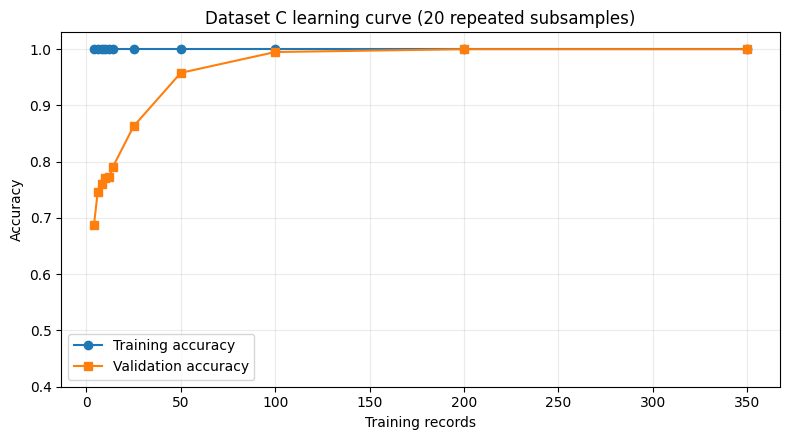

In [17]:
indices = list(range(len(DATASET_C)))
random.Random(SEED).shuffle(indices)
train_indices, validation_indices = indices[:350], indices[350:]
C_TRAIN_POOL = [DATASET_C[i] for i in train_indices]
C_VALIDATION = [DATASET_C[i] for i in validation_indices]
C_VALIDATION_CLEAN = C_VALIDATION

learning_sizes = [4, 6, 8, 10, 12, 14, 25, 50, 100, 200, 350]
learning_train_scores, learning_validation_scores = [], []
for size in learning_sizes:
    train_scores, validation_scores = [], []
    for rep in range(20):
        sample = random.Random(3000 + rep).sample(C_TRAIN_POOL, size)
        model = build_id3(sample, B_ATTRIBUTES, B_DOMAINS)
        train_scores.append(classification_metrics(sample, model)["accuracy"])
        validation_scores.append(classification_metrics(C_VALIDATION, model)["accuracy"])
    learning_train_scores.append(float(np.mean(train_scores)))
    learning_validation_scores.append(float(np.mean(validation_scores)))

learning_curve_table = pd.DataFrame({"Training size": learning_sizes,
                                     "Mean training accuracy": learning_train_scores,
                                     "Mean validation accuracy": learning_validation_scores})
display(learning_curve_table.round(4))

plt.figure(figsize=(8,4.5))
plt.plot(learning_sizes, learning_train_scores, marker="o", label="Training accuracy")
plt.plot(learning_sizes, learning_validation_scores, marker="s", label="Validation accuracy")
plt.xlabel("Training records")
plt.ylabel("Accuracy")
plt.title("Dataset C learning curve (20 repeated subsamples)")
plt.ylim(0.4,1.03)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "learning_curve.png", dpi=180)
plt.show()

### Task 10A.4 – Model-complexity curve

The tree is trained at maximum depths 0 through 4. Since there are four available predictors, depth 4 is the maximum possible path length for this ID3 implementation.

,Maximum depth,Actual depth,Nodes,Leaves,Training accuracy,Validation accuracy
0,0,0,1,1,0.5086,0.4733
1,1,1,4,3,0.7486,0.7533
2,2,2,10,6,0.8400,0.8400
3,3,3,18,10,0.8657,0.8667
4,4,4,26,14,1.0000,1.0000


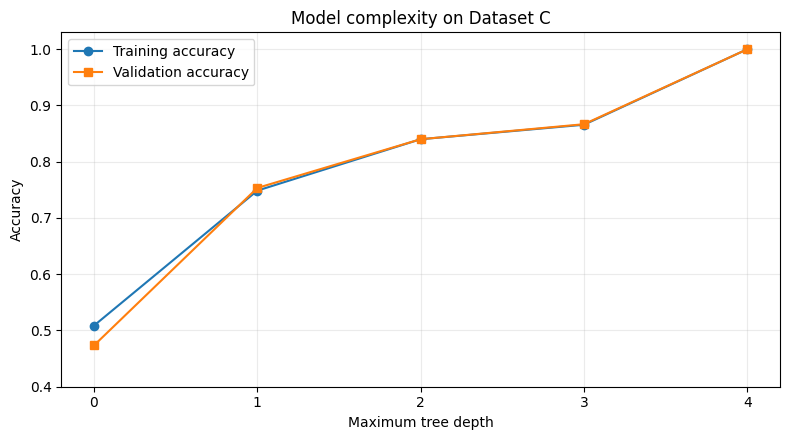

In [18]:
complexity_rows = []
for depth in range(5):
    model = build_id3(C_TRAIN_POOL, B_ATTRIBUTES, B_DOMAINS, max_depth=depth)
    train_m = classification_metrics(C_TRAIN_POOL, model)
    val_m = classification_metrics(C_VALIDATION, model)
    nodes, leaves, actual_depth = tree_statistics(model)
    complexity_rows.append({"Maximum depth": depth, "Actual depth": actual_depth,
                            "Nodes": nodes, "Leaves": leaves,
                            "Training accuracy": train_m["accuracy"],
                            "Validation accuracy": val_m["accuracy"]})
complexity_table = pd.DataFrame(complexity_rows)
display(complexity_table.round(4))

plt.figure(figsize=(8,4.5))
plt.plot(complexity_table["Maximum depth"], complexity_table["Training accuracy"], marker="o", label="Training accuracy")
plt.plot(complexity_table["Maximum depth"], complexity_table["Validation accuracy"], marker="s", label="Validation accuracy")
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.title("Model complexity on Dataset C")
plt.xticks(range(5))
plt.ylim(0.4,1.03)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "tree_complexity.png", dpi=180)
plt.show()

### Task 10A.5 – Effect of 0%, 5% and 10% label noise

The exact requested proportion of labels is flipped using a deterministic random seed. Results are shown against both the noisy validation labels and the original clean validation labels. The controlled tree uses maximum depth 2, `min_samples_split=10` and minimum information gain 0.01.

,Noise,Model,Depth,Nodes,Leaves,Noisy training accuracy,Noisy validation accuracy,Clean validation accuracy
0,0.00,Fully grown,4,26,14,1.0000,1.0000,1.00
1,0.00,"Controlled (depth 2, min split 10, min gain .01)",2,10,6,0.8400,0.8400,0.84
2,0.05,Fully grown,4,44,23,0.9514,0.9467,1.00
3,0.05,"Controlled (depth 2, min split 10, min gain .01)",2,10,6,0.7943,0.7600,0.80
4,0.10,Fully grown,4,46,24,0.8914,0.9200,1.00
5,0.10,"Controlled (depth 2, min split 10, min gain .01)",2,10,6,0.7657,0.7733,0.84


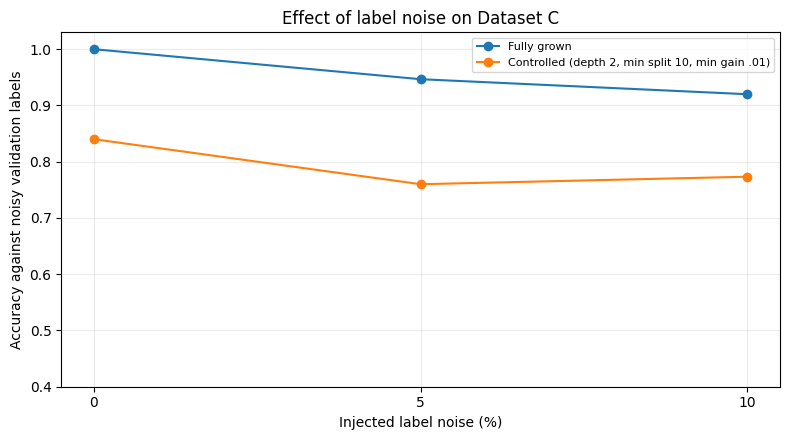

In [19]:
noise_results = []
for noise_rate in (0.0, 0.05, 0.10):
    flip_rng = random.Random(1000 + int(noise_rate * 100))
    flip_indices = set(flip_rng.sample(range(len(DATASET_C)), round(len(DATASET_C) * noise_rate)))
    noisy_data = []
    for i, (name, instance, label) in enumerate(DATASET_C):
        new_label = ("No" if label == "Yes" else "Yes") if i in flip_indices else label
        noisy_data.append((name, instance, new_label))
    noisy_train = [noisy_data[i] for i in train_indices]
    noisy_validation = [noisy_data[i] for i in validation_indices]

    model_settings = {
        "Fully grown": {},
        "Controlled (depth 2, min split 10, min gain .01)": {
            "max_depth": 2, "min_samples_split": 10, "min_gain": 0.01
        },
    }
    for model_name, settings in model_settings.items():
        model = build_id3(noisy_train, B_ATTRIBUTES, B_DOMAINS, **settings)
        train_m = classification_metrics(noisy_train, model)
        noisy_val_m = classification_metrics(noisy_validation, model)
        clean_val_m = classification_metrics(C_VALIDATION_CLEAN, model)
        nodes, leaves, depth = tree_statistics(model)
        noise_results.append({"Noise": noise_rate, "Model": model_name,
                              "Depth": depth, "Nodes": nodes, "Leaves": leaves,
                              "Noisy training accuracy": train_m["accuracy"],
                              "Noisy validation accuracy": noisy_val_m["accuracy"],
                              "Clean validation accuracy": clean_val_m["accuracy"]})

noise_table = pd.DataFrame(noise_results)
display(noise_table.round(4))

plt.figure(figsize=(8,4.5))
for model_name, subset in noise_table.groupby("Model", sort=False):
    plt.plot(subset["Noise"]*100, subset["Noisy validation accuracy"], marker="o", label=model_name)
plt.xlabel("Injected label noise (%)")
plt.ylabel("Accuracy against noisy validation labels")
plt.title("Effect of label noise on Dataset C")
plt.xticks([0,5,10])
plt.ylim(0.4,1.03)
plt.grid(alpha=0.25)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "noise_effect.png", dpi=180)
plt.show()

### Task 10A.6 – Candidate Elimination versus decision trees on Dataset B

Candidate Elimination assumes one consistent conjunctive target hypothesis. Dataset B is not consistent with that restricted hypothesis space: the version space becomes empty at the fourth example. ID3 can still construct a tree because its representation is more flexible.

,Example,Label,|Version space|,S,G
0,1,Yes,16,"{ ⟨Low, Irregular, Passive, Weak⟩ }","{ ⟨?, ?, ?, ?⟩ }"
1,2,Yes,8,"{ ⟨Low, Irregular, Passive, ?⟩ }","{ ⟨?, ?, ?, ?⟩ }"
2,3,Yes,2,"{ ⟨Low, ?, ?, ?⟩ }","{ ⟨?, ?, ?, ?⟩ }"
3,4,No,0,"{ ⟨Low, ?, ?, ?⟩ }",{ }
4,5,Yes,0,"{ ⟨?, ?, ?, ?⟩ }",{ }
5,6,No,0,"{ ⟨?, ?, ?, ?⟩ }",{ }
6,7,Yes,0,"{ ⟨?, ?, ?, ?⟩ }",{ }
7,8,No,0,"{ ⟨?, ?, ?, ?⟩ }",{ }
8,9,Yes,0,"{ ⟨?, ?, ?, ?⟩ }",{ }
9,10,No,0,"{ ⟨?, ?, ?, ?⟩ }",{ }


Candidate Elimination version-space collapse at Dataset B example: 4


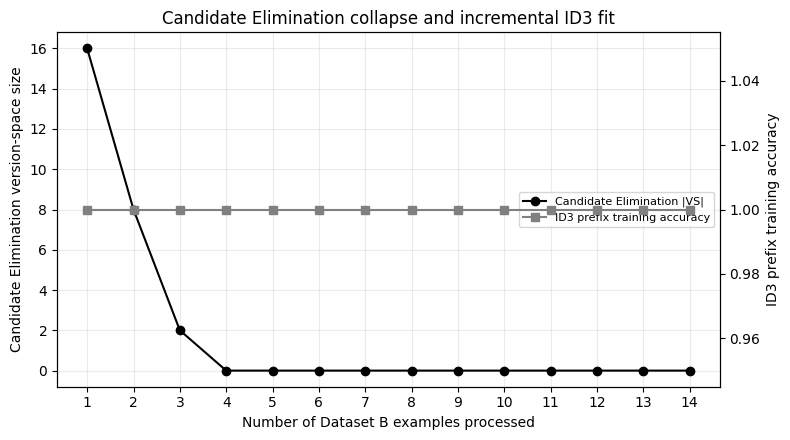

,Method,Representation,Label behaviour,Observed result,Strength,Limitation
0,Candidate Elimination,Conjunctive constraints,"Requires noise-free, consistent labels",Empty version space at B example 4,Compact boundary description when consistent,Cannot represent Dataset B target under this bias
1,ID3 decision tree,Recursive attribute tests / disjunction across branches,Can fit mixed patterns; still sensitive to noise,Builds a 100% training-fit tree,IF–THEN path explanations,Small data can produce unstable deep trees


In [20]:
S_B, G_B, TRACE_B = candidate_elimination(DATASET_B, B_DOMAINS)
ce_b_table = pd.DataFrame([
    {"Example": r["example"], "Label": r["label"], "|Version space|": len(r["version_space"]),
     "S": display_hypotheses(r["S"]), "G": display_hypotheses(r["G"])}
    for r in TRACE_B
])
display(ce_b_table)
collapse_step = next((i+1 for i,r in enumerate(TRACE_B) if len(r["version_space"]) == 0), None)
print("Candidate Elimination version-space collapse at Dataset B example:", collapse_step)

# Compare incremental Candidate Elimination VS size with incremental ID3 training accuracy.
ce_sizes, incremental_tree_acc = [], []
for end in range(1, len(DATASET_B)+1):
    prefix = DATASET_B[:end]
    s_prefix, g_prefix, trace_prefix = candidate_elimination(prefix, B_DOMAINS)
    ce_sizes.append(len(enumerate_version_space(s_prefix, g_prefix, B_DOMAINS)))
    prefix_tree = build_id3(prefix, B_ATTRIBUTES, B_DOMAINS)
    incremental_tree_acc.append(classification_metrics(prefix, prefix_tree)["accuracy"])

fig, ax1 = plt.subplots(figsize=(8,4.5))
ax1.plot(range(1,15), ce_sizes, marker="o", label="Candidate Elimination |VS|", color="black")
ax1.set_xlabel("Number of Dataset B examples processed")
ax1.set_ylabel("Candidate Elimination version-space size")
ax1.set_xticks(range(1,15))
ax1.grid(alpha=0.25)
ax2 = ax1.twinx()
ax2.plot(range(1,15), incremental_tree_acc, marker="s", label="ID3 prefix training accuracy", color="gray")
ax2.set_ylabel("ID3 prefix training accuracy")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, loc="center right", fontsize=8)
plt.title("Candidate Elimination collapse and incremental ID3 fit")
plt.tight_layout()
plt.savefig(FIG_DIR / "ce_vs_tree.png", dpi=180)
plt.show()

method_comparison = pd.DataFrame([
    ["Candidate Elimination", "Conjunctive constraints", "Requires noise-free, consistent labels", "Empty version space at B example 4", "Compact boundary description when consistent", "Cannot represent Dataset B target under this bias"],
    ["ID3 decision tree", "Recursive attribute tests / disjunction across branches", "Can fit mixed patterns; still sensitive to noise", "Builds a 100% training-fit tree", "IF–THEN path explanations", "Small data can produce unstable deep trees"],
], columns=["Method", "Representation", "Label behaviour", "Observed result", "Strength", "Limitation"])
display(method_comparison)

## Task 11 – Day-4 design challenge

The new records are added exactly as shown in the assignment. The code tests three separate Candidate Elimination sequences and rebuilds ID3 after appending N1–N3.

In [21]:
# Additional concept-learning records from the Day-4 challenge.
E6 = ("E6", ("Low", "Irregular", "Low", "Weak", "Passive", "No"), "No")
E7 = ("E7", ("Medium", "Regular", "High", "Weak", "Passive", "No"), "Yes")
E8 = ("E8", ("Low", "Regular", "High", "Strong", "Active", "Yes"), "Yes")

# Use E6 alone after E1-E5; use E7 then E8 cumulatively after E1-E5.
challenge_sequences = {
    "E1–E5 then E6": DATASET_A + [E6],
    "E1–E5 then E7": DATASET_A + [E7],
    "E1–E5 then E7 then E8": DATASET_A + [E7, E8],
}
challenge_results = []
for label, rows in challenge_sequences.items():
    s_new, g_new, tr_new = candidate_elimination(rows, A_DOMAINS)
    vs_new = enumerate_version_space(s_new, g_new, A_DOMAINS)
    last_rows = tr_new[-(1 if label.endswith("E6") or label.endswith("E7") else 2):]
    challenge_results.append({"Sequence": label, "Final S": display_hypotheses(sorted(s_new)),
                              "Final G": display_hypotheses(sorted(g_new)),
                              "Version-space size": len(vs_new),
                              "Collapsed": len(vs_new) == 0})
    print("\n", label)
    for item in last_rows:
        print(item["example"], item["label"], "S=", display_hypotheses(item["S"]),
              "G=", display_hypotheses(item["G"]), "|VS|=", len(item["version_space"]))
display(pd.DataFrame(challenge_results))

print("E6 is a direct contradiction: it repeats E1's exact feature vector but has the opposite label.")
print("No deterministic concept can classify the same input as both Yes and No; a strict Candidate Elimination version space must therefore become empty.")
print("E7 is a new positive combination that can be accommodated temporarily, but E8 then removes the remaining conjunctive boundary and collapses the space.")


 E1–E5 then E6
E6 No S= { ⟨Low, Irregular, ?, ?, Passive, ?⟩ } G= {  } |VS|= 0

 E1–E5 then E7
E7 Yes S= { ⟨?, ?, ?, ?, Passive, ?⟩ } G= { ⟨?, ?, ?, ?, Passive, ?⟩ } |VS|= 1

 E1–E5 then E7 then E8
E7 Yes S= { ⟨?, ?, ?, ?, Passive, ?⟩ } G= { ⟨?, ?, ?, ?, Passive, ?⟩ } |VS|= 1
E8 Yes S= { ⟨?, ?, ?, ?, ?, ?⟩ } G= {  } |VS|= 0


,Sequence,Final S,Final G,Version-space size,Collapsed
0,E1–E5 then E6,"{ ⟨Low, Irregular, ?, ?, Passive, ?⟩ }",{ },0,True
1,E1–E5 then E7,"{ ⟨?, ?, ?, ?, Passive, ?⟩ }","{ ⟨?, ?, ?, ?, Passive, ?⟩ }",1,False
2,E1–E5 then E7 then E8,"{ ⟨?, ?, ?, ?, ?, ?⟩ }",{ },0,True


E6 is a direct contradiction: it repeats E1's exact feature vector but has the opposite label.
No deterministic concept can classify the same input as both Yes and No; a strict Candidate Elimination version space must therefore become empty.
E7 is a new positive combination that can be accommodated temporarily, but E8 then removes the remaining conjunctive boundary and collapses the space.


In [22]:
# Additional decision-tree records from the Day-4 challenge.
N1 = ("N1", ("Very Low", "Irregular", "Passive", "Weak"), "Yes")
N2 = ("N2", ("High", "Regular", "Active", "Strong"), "Yes")
N3 = ("N3", ("Low", "Regular", "Passive", "Weak"), "Yes")
NEW_RECORDS = [N1, N2, N3]

# The Attendance domain is extended to include the newly observed value.
B_DOMAINS_DAY4 = [["Very Low", "Low", "Medium", "High"], *B_DOMAINS[1:]]
OLD_TREE_PREDICTIONS = [(name, y, predict_tree(TREE_B, x)) for name,x,y in NEW_RECORDS]
UPDATED_DATASET_B = DATASET_B + NEW_RECORDS
DAY4_GAIN_LOG = []
TREE_DAY4 = build_id3(UPDATED_DATASET_B, B_ATTRIBUTES, B_DOMAINS_DAY4, gain_log=DAY4_GAIN_LOG)
DAY4_METRICS_TRAIN = classification_metrics(UPDATED_DATASET_B, TREE_DAY4)

print("Predictions from original tree before adding new records:")
display(pd.DataFrame(OLD_TREE_PREDICTIONS, columns=["Record", "Actual", "Old-tree prediction"]))
print("Updated tree after adding N1–N3:")
print(tree_as_text(TREE_DAY4, B_ATTRIBUTES))
print("Updated tree statistics (nodes, leaves, depth):", tree_statistics(TREE_DAY4))
print("Updated training metrics:", {k: round(v,4) for k,v in DAY4_METRICS_TRAIN.items() if k in ["accuracy","precision","recall","f1"]})
display(pd.DataFrame([(name,y,predict_tree(TREE_DAY4,x)) for name,x,y in NEW_RECORDS],
                     columns=["Record","Actual","Updated-tree prediction"]))

Predictions from original tree before adding new records:


,Record,Actual,Old-tree prediction
0,N1,Yes,Yes
1,N2,Yes,No
2,N3,Yes,Yes


Updated tree after adding N1–N3:
Split on PriorCGPA  counts={'Yes': 10, 'No': 7}
  [Weak]
    Split on Attendance  counts={'Yes': 8, 'No': 1}
      [Very Low]
        Predict Yes  counts={'Yes': 1}
      [Low]
        Predict Yes  counts={'Yes': 4}
      [Medium]
        Predict Yes  counts={'Yes': 2}
      [High]
        Split on Assignments  counts={'Yes': 1, 'No': 1}
          [Irregular]
            Predict Yes  counts={'Yes': 1}
          [Regular]
            Predict No  counts={'No': 1}
  [Strong]
    Split on Attendance  counts={'Yes': 2, 'No': 6}
      [Very Low]
        Predict No  counts={}
      [Low]
        Split on Assignments  counts={'Yes': 1, 'No': 1}
          [Irregular]
            Predict Yes  counts={'Yes': 1}
          [Regular]
            Predict No  counts={'No': 1}
      [Medium]
        Predict No  counts={'No': 3}
      [High]
        Split on Assignments  counts={'No': 2, 'Yes': 1}
          [Irregular]
            Predict No  counts={'No': 1}
          [

,Record,Actual,Updated-tree prediction
0,N1,Yes,Yes
1,N2,Yes,Yes
2,N3,Yes,Yes


### Task 11 – Recall threshold and human-readable explanations

A deployment system should tune the AtRisk threshold on a representative validation set, not choose it from the six-record Test Set T. This code demonstrates the precision–recall trade-off using the leaf class frequencies of the learned tree. It also prints a plain-language path for each flagged record.

In [23]:
def predict_risk_probability(node: TreeNode, instance: Sequence[str]) -> float:
    current = node
    while current.attribute is not None:
        value = instance[current.attribute]
        if value not in current.branches:
            counts = current.counts
            total = sum(counts.values())
            return counts["Yes"] / total if total else 1.0
        child = current.branches[value]
        if sum(child.counts.values()) == 0:
            counts = current.counts
            total = sum(counts.values())
            return counts["Yes"] / total if total else 1.0
        current = child
    total = sum(current.counts.values())
    return current.counts["Yes"] / total if total else (1.0 if current.prediction == "Yes" else 0.0)


def threshold_metrics(rows, model, threshold):
    tp=fp=tn=fn=0
    for _,x,actual in rows:
        predicted = "Yes" if predict_risk_probability(model,x) >= threshold else "No"
        if actual == "Yes" and predicted == "Yes": tp += 1
        elif actual == "No" and predicted == "Yes": fp += 1
        elif actual == "No" and predicted == "No": tn += 1
        else: fn += 1
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    return {"TP":tp,"FP":fp,"TN":tn,"FN":fn,
            "accuracy":(tp+tn)/len(rows),"precision":precision,"recall":recall,"f1":f1}

threshold_rows = []
for threshold in [0.25, 0.35, 0.50, 0.65, 0.75]:
    m = threshold_metrics(TEST_SET_T, TREE_B, threshold)
    threshold_rows.append({"Threshold": threshold, **m})
display(pd.DataFrame(threshold_rows).round(4))
print("Interpretation: lowering the threshold can increase recall by flagging more students, but it can also increase false positives and reduce precision.")
print("The 90% recall requirement must be confirmed on a sufficiently large, representative, time-separated validation/test cohort.")


def explain_prediction(node: TreeNode, instance, attributes, threshold=0.5):
    current = node
    path = []
    while current.attribute is not None:
        attr = attributes[current.attribute]
        value = instance[current.attribute]
        path.append(f"{attr} = {value}")
        if value not in current.branches or sum(current.branches[value].counts.values()) == 0:
            counts = current.counts
            break
        current = current.branches[value]
        counts = current.counts
    total = sum(counts.values())
    probability = counts["Yes"] / total if total else (1.0 if current.prediction == "Yes" else 0.0)
    prediction = "Yes" if probability >= threshold else "No"
    return {"Path": " AND ".join(path) if path else "No split",
            "Leaf counts": dict(counts), "Estimated AtRisk proportion": probability,
            "Threshold": threshold, "Prediction": prediction}

print("Example explanations for the three new records (threshold=0.50):")
for name, instance, actual in NEW_RECORDS:
    print(name, explain_prediction(TREE_DAY4, instance, B_ATTRIBUTES, threshold=0.5))

,Threshold,TP,FP,TN,FN,accuracy,precision,recall,f1
0,0.25,2,2,1,1,0.5,0.5,0.6667,0.5714
1,0.35,2,2,1,1,0.5,0.5,0.6667,0.5714
2,0.50,2,2,1,1,0.5,0.5,0.6667,0.5714
3,0.65,2,2,1,1,0.5,0.5,0.6667,0.5714
4,0.75,2,2,1,1,0.5,0.5,0.6667,0.5714


Interpretation: lowering the threshold can increase recall by flagging more students, but it can also increase false positives and reduce precision.
The 90% recall requirement must be confirmed on a sufficiently large, representative, time-separated validation/test cohort.
Example explanations for the three new records (threshold=0.50):
N1 {'Path': 'PriorCGPA = Weak AND Attendance = Very Low', 'Leaf counts': {'Yes': 1}, 'Estimated AtRisk proportion': 1.0, 'Threshold': 0.5, 'Prediction': 'Yes'}
N2 {'Path': 'PriorCGPA = Strong AND Attendance = High AND Assignments = Regular AND LMS = Active', 'Leaf counts': {'Yes': 1}, 'Estimated AtRisk proportion': 1.0, 'Threshold': 0.5, 'Prediction': 'Yes'}
N3 {'Path': 'PriorCGPA = Weak AND Attendance = Low', 'Leaf counts': {'Yes': 4}, 'Estimated AtRisk proportion': 1.0, 'Threshold': 0.5, 'Prediction': 'Yes'}


## Final reproducibility summary

Run this last cell after all previous cells. It reports the main benchmark results, writes the synthetic dataset, and confirms that all expected plots were generated. Numerical results from the 5- and 14-record datasets are descriptive only; they are too small to establish deployment-level performance.

In [24]:
summary_rows = [
    ["Candidate Elimination on A", len(FINAL_VS_A), "Survives with two consistent conjunctive hypotheses"],
    ["Candidate Elimination on B", 0, f"Version space collapses at example {collapse_step}"],
    ["ID3 on B – training accuracy", train_metrics_B["accuracy"], f"{nodes_B} nodes, {leaves_B} leaves, depth {depth_B}"],
    ["ID3 on Test Set T – accuracy", TEST_METRICS_FULL["accuracy"], f"Recall={TEST_METRICS_FULL['recall']:.3f}; F1={TEST_METRICS_FULL['f1']:.3f}"],
    ["5-fold CV on B+T – accuracy", CV_METRICS["accuracy"], f"Recall={CV_METRICS['recall']:.3f}; F1={CV_METRICS['f1']:.3f}"],
    ["Synthetic Dataset C", len(DATASET_C), "500 rows; fixed synthetic label rule; seed 2026"],
    ["Day-4 Candidate Elimination with E6", len(enumerate_version_space(*candidate_elimination(DATASET_A+[E6], A_DOMAINS)[:2], A_DOMAINS)), "Direct contradictory label causes collapse"],
    ["Day-4 updated tree", DAY4_METRICS_TRAIN["accuracy"], f"{tree_statistics(TREE_DAY4)[0]} nodes; {tree_statistics(TREE_DAY4)[1]} leaves; depth {tree_statistics(TREE_DAY4)[2]}"],
]
display(pd.DataFrame(summary_rows, columns=["Experiment", "Result", "Interpretation"]))

print("\nGenerated files:")
print(" -", dataset_c_path)
for filename in ["learning_curve.png", "tree_complexity.png", "noise_effect.png", "ce_vs_tree.png"]:
    path = FIG_DIR / filename
    print(" -", path, "exists:", path.exists())
print("\nAll assignment code cells completed.")

,Experiment,Result,Interpretation
0,Candidate Elimination on A,2.0,Survives with two consistent conjunctive hypotheses
1,Candidate Elimination on B,0.0,Version space collapses at example 4
2,ID3 on B – training accuracy,1.0,"13 nodes, 8 leaves, depth 3"
3,ID3 on Test Set T – accuracy,0.5,Recall=0.667; F1=0.571
4,5-fold CV on B+T – accuracy,0.6,Recall=0.700; F1=0.636
5,Synthetic Dataset C,500.0,500 rows; fixed synthetic label rule; seed 2026
6,Day-4 Candidate Elimination with E6,0.0,Direct contradictory label causes collapse
7,Day-4 updated tree,1.0,19 nodes; 12 leaves; depth 4



Generated files:
 - /content/dataset_C_synthetic.csv
 - /content/figures/learning_curve.png exists: True
 - /content/figures/tree_complexity.png exists: True
 - /content/figures/noise_effect.png exists: True
 - /content/figures/ce_vs_tree.png exists: True

All assignment code cells completed.
